#**1. Import Library**

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

#**2. Load Dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# GANTI sesuai lokasi file train.csv kamu
DATA_PATH = "/content/drive/MyDrive/nyc_taxi_trip_duration.csv"

OUTPUT_DIR = Path("/content/output_nyc_taxi_duration")
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Shape awal:", df.shape)
display(df.head())

Shape awal: (729322, 11)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id1080784,2,2016-02-29 16:40:21,2016-02-29 16:47:01,1,-73.953918,40.778873,-73.963875,40.771164,N,400
1,id0889885,1,2016-03-11 23:35:37,2016-03-11 23:53:57,2,-73.988312,40.731743,-73.994751,40.694931,N,1100
2,id0857912,2,2016-02-21 17:59:33,2016-02-21 18:26:48,2,-73.997314,40.721458,-73.948029,40.774918,N,1635
3,id3744273,2,2016-01-05 09:44:31,2016-01-05 10:03:32,6,-73.961670,40.759720,-73.956779,40.780628,N,1141
4,id0232939,1,2016-02-17 06:42:23,2016-02-17 06:56:31,1,-74.017120,40.708469,-73.988182,40.740631,N,848


#**3. Data Understanding**

In [ ]:
print("="*60)
print("DATA UNDERSTANDING")
print("="*60)

print("\nInfo Dataset:")
print(df.info())

print("\nMissing Value:")
display(df.isna().sum())

print("\nDuplicate:")
print(df.duplicated().sum())

print("\nStatistik Deskriptif:")
display(df.describe())

DATA UNDERSTANDING

Info Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 729322 entries, 0 to 729321
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  729322 non-null  object 
 1   vendor_id           729322 non-null  int64  
 2   pickup_datetime     729322 non-null  object 
 3   dropoff_datetime    729322 non-null  object 
 4   passenger_count     729322 non-null  int64  
 5   pickup_longitude    729322 non-null  float64
 6   pickup_latitude     729322 non-null  float64
 7   dropoff_longitude   729322 non-null  float64
 8   dropoff_latitude    729322 non-null  float64
 9   store_and_fwd_flag  729322 non-null  object 
 10  trip_duration       729322 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 61.2+ MB
None

Missing Value:


,0
id,0
vendor_id,0
pickup_datetime,0
dropoff_datetime,0
passenger_count,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
store_and_fwd_flag,0



Duplicate:
0

Statistik Deskriptif:


,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,729322.000000,729322.000000,729322.000000,729322.000000,729322.000000,729322.000000,7.293220e+05
mean,1.535403,1.662055,-73.973513,40.750919,-73.973422,40.751775,9.522291e+02
std,0.498745,1.312446,0.069754,0.033594,0.069588,0.036037,3.864626e+03
min,1.000000,0.000000,-121.933342,34.712234,-121.933304,32.181141,1.000000e+00
25%,1.000000,1.000000,-73.991859,40.737335,-73.991318,40.735931,3.970000e+02
50%,2.000000,1.000000,-73.981758,40.754070,-73.979759,40.754509,6.630000e+02
75%,2.000000,2.000000,-73.967361,40.768314,-73.963036,40.769741,1.075000e+03
max,2.000000,9.000000,-65.897385,51.881084,-65.897385,43.921028,1.939736e+06


#**4. Data Cleaning**

In [ ]:
# Standarisasi nama kolom
df.columns = df.columns.str.lower().str.strip()

# Konversi datetime
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce")
df["dropoff_datetime"] = pd.to_datetime(df["dropoff_datetime"], errors="coerce")

# Hapus duplikat
df = df.drop_duplicates()

# Hapus missing value penting
df = df.dropna(subset=[
    "pickup_datetime",
    "dropoff_datetime",
    "passenger_count",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "trip_duration"
])

print("Shape setelah cleaning awal:", df.shape)

Shape setelah cleaning awal: (729322, 11)


#**5. Filter Data Tidak Logis**

In [ ]:
# Trip duration dari detik ke menit
df["trip_duration_min"] = df["trip_duration"] / 60

# Filter data logis
df = df[
    (df["passenger_count"] >= 1) &
    (df["passenger_count"] <= 6) &
    (df["trip_duration_min"] > 0) &
    (df["trip_duration_min"] <= 300)
]

# Filter koordinat area NYC
LAT_MIN, LAT_MAX = 40.45, 40.95
LON_MIN, LON_MAX = -74.30, -73.65

df = df[
    df["pickup_latitude"].between(LAT_MIN, LAT_MAX) &
    df["dropoff_latitude"].between(LAT_MIN, LAT_MAX) &
    df["pickup_longitude"].between(LON_MIN, LON_MAX) &
    df["dropoff_longitude"].between(LON_MIN, LON_MAX)
]

print("Shape setelah filter data logis:", df.shape)

Shape setelah filter data logis: (727853, 12)


#**6. Feature Engineering**

In [ ]:
# Fitur waktu
df["pickup_date"] = df["pickup_datetime"].dt.date
df["pickup_hour"] = df["pickup_datetime"].dt.hour
df["pickup_day"] = df["pickup_datetime"].dt.day
df["pickup_month"] = df["pickup_datetime"].dt.month
df["pickup_weekday"] = df["pickup_datetime"].dt.day_name()
df["pickup_weekday_num"] = df["pickup_datetime"].dt.weekday

# Weekend
df["is_weekend"] = df["pickup_weekday_num"].isin([5, 6]).astype(int)

# Kategori waktu
def time_period(hour):
    if 5 <= hour <= 10:
        return "Morning"
    elif 11 <= hour <= 15:
        return "Afternoon"
    elif 16 <= hour <= 20:
        return "Evening"
    else:
        return "Night"

df["time_period"] = df["pickup_hour"].apply(time_period)

In [ ]:
# Menghitung jarak dengan rumus Haversine
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  # kilometer

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

df["distance_km"] = haversine_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

# Kecepatan rata-rata
df["speed_kmph"] = df["distance_km"] / (df["trip_duration_min"] / 60)

# Filter kecepatan logis
df = df[
    (df["distance_km"] > 0) &
    (df["distance_km"] <= 100) &
    (df["speed_kmph"] > 0) &
    (df["speed_kmph"] <= 150)
]

print("Shape setelah feature engineering:", df.shape)
display(df.head())

Shape setelah feature engineering: (724966, 22)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,...,pickup_date,pickup_hour,pickup_day,pickup_month,pickup_weekday,pickup_weekday_num,is_weekend,time_period,distance_km,speed_kmph
0,id1080784,2,2016-02-29 16:40:21,2016-02-29 16:47:01,1,-73.953918,40.778873,-73.963875,40.771164,N,...,2016-02-29,16,29,2,Monday,0,0,Evening,1.199073,10.791654
1,id0889885,1,2016-03-11 23:35:37,2016-03-11 23:53:57,2,-73.988312,40.731743,-73.994751,40.694931,N,...,2016-03-11,23,11,3,Friday,4,0,Night,4.129111,13.513454
2,id0857912,2,2016-02-21 17:59:33,2016-02-21 18:26:48,2,-73.997314,40.721458,-73.948029,40.774918,N,...,2016-02-21,17,21,2,Sunday,6,1,Evening,7.250753,15.964960
3,id3744273,2,2016-01-05 09:44:31,2016-01-05 10:03:32,6,-73.961670,40.759720,-73.956779,40.780628,N,...,2016-01-05,9,5,1,Tuesday,1,0,Morning,2.361097,7.449562
4,id0232939,1,2016-02-17 06:42:23,2016-02-17 06:56:31,1,-74.017120,40.708469,-73.988182,40.740631,N,...,2016-02-17,6,17,2,Wednesday,2,0,Morning,4.328534,18.375851


#**7. Simpan Data Bersih**

In [ ]:
CLEANED_PATH = OUTPUT_DIR / "nyc_taxi_trip_duration_cleaned.csv"

df.to_csv(CLEANED_PATH, index=False)

print("Data bersih disimpan:", CLEANED_PATH)

Data bersih disimpan: /content/output_nyc_taxi_duration/nyc_taxi_trip_duration_cleaned.csv


# EDA

#**8. Distribusi Durasi Perjalanan**

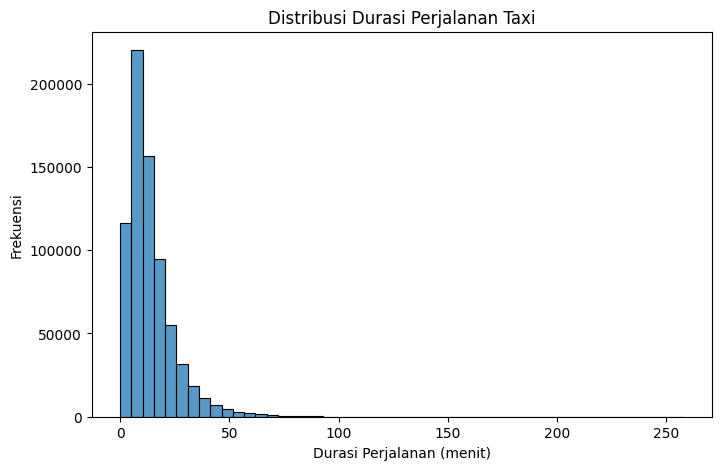

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["trip_duration_min"], bins=50)
plt.title("Distribusi Durasi Perjalanan Taxi")
plt.xlabel("Durasi Perjalanan (menit)")
plt.ylabel("Frekuensi")
plt.show()

#**9. Distribusi Jarak Perjalanan**

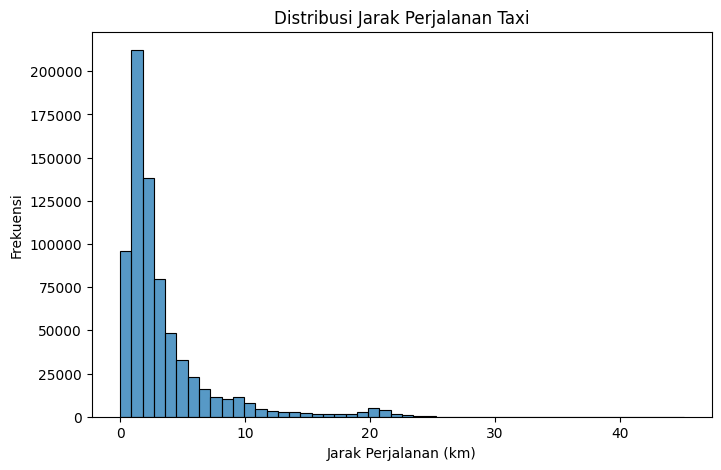

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["distance_km"], bins=50)
plt.title("Distribusi Jarak Perjalanan Taxi")
plt.xlabel("Jarak Perjalanan (km)")
plt.ylabel("Frekuensi")
plt.show()

#**10. Peak Hour**

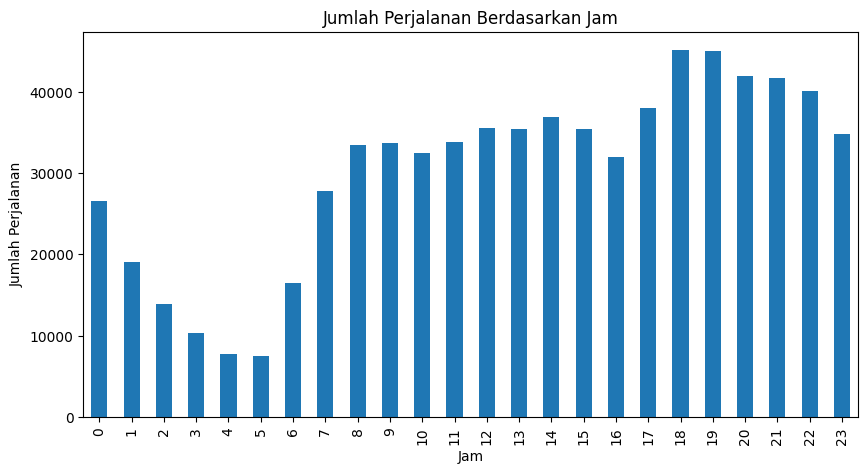

In [ ]:
hourly_trip = df.groupby("pickup_hour").size()

plt.figure(figsize=(10,5))
hourly_trip.plot(kind="bar")
plt.title("Jumlah Perjalanan Berdasarkan Jam")
plt.xlabel("Jam")
plt.ylabel("Jumlah Perjalanan")
plt.show()

#**11. Korelasi Fitur Numerik**

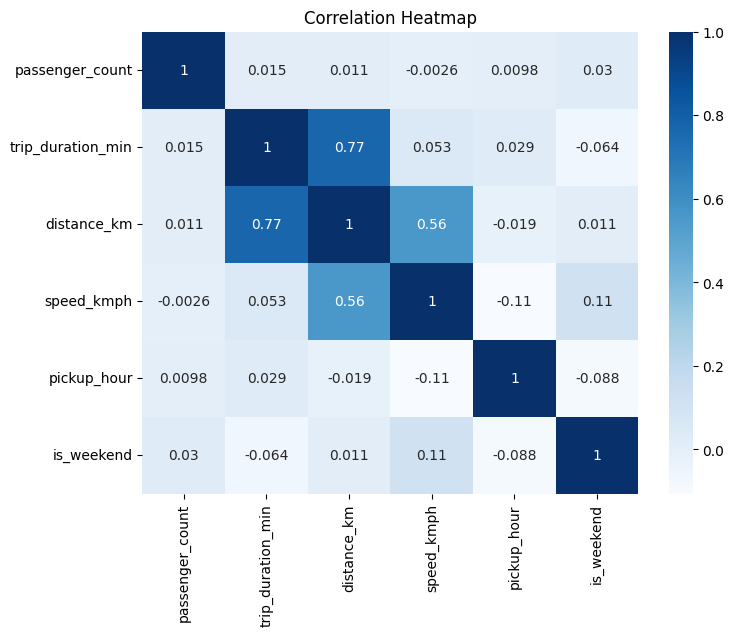

In [ ]:
corr_cols = [
    "passenger_count",
    "trip_duration_min",
    "distance_km",
    "speed_kmph",
    "pickup_hour",
    "is_weekend"
]

plt.figure(figsize=(8,6))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="Blues")
plt.title("Correlation Heatmap")
plt.show()

#Time-Series Mining

#**12. Hourly Summary**

In [ ]:
hourly_summary = (
    df.groupby(df["pickup_datetime"].dt.floor("H"))
    .agg(
        trip_count=("id", "count"),
        avg_duration=("trip_duration_min", "mean"),
        avg_distance=("distance_km", "mean"),
        avg_speed=("speed_kmph", "mean")
    )
    .reset_index()
    .rename(columns={"pickup_datetime": "pickup_hour_time"})
)

display(hourly_summary.head())

,pickup_hour_time,trip_count,avg_duration,avg_distance,avg_speed
0,2016-01-01 00:00:00,273,13.722527,3.656289,15.660288
1,2016-01-01 01:00:00,284,14.287617,3.698776,15.694567
2,2016-01-01 02:00:00,236,13.814831,4.103919,17.154236
3,2016-01-01 03:00:00,230,13.752464,4.117404,17.426412
4,2016-01-01 04:00:00,164,14.315447,4.603059,18.216070


#**13. Daily Summary + Moving Average**

In [ ]:
daily_summary = (
    df.groupby("pickup_date")
    .agg(
        trip_count=("id", "count"),
        avg_duration=("trip_duration_min", "mean"),
        avg_distance=("distance_km", "mean"),
        avg_speed=("speed_kmph", "mean")
    )
    .reset_index()
)

daily_summary["moving_avg_3"] = daily_summary["trip_count"].rolling(window=3).mean()
daily_summary["moving_avg_7"] = daily_summary["trip_count"].rolling(window=7).mean()

display(daily_summary.head())

,pickup_date,trip_count,avg_duration,avg_distance,avg_speed,moving_avg_3,moving_avg_7
0,2016-01-01,3558,12.097972,3.896349,18.358746,NaN,NaN
1,2016-01-02,3207,11.739019,3.526924,16.937072,NaN,NaN
2,2016-01-03,3125,11.978592,4.001686,18.437493,3296.666667,NaN
3,2016-01-04,3320,11.798695,3.435539,16.195548,3217.333333,NaN
4,2016-01-05,3563,12.196370,3.262306,14.928411,3336.000000,NaN


#**14. Visualisasi Daily Trend**

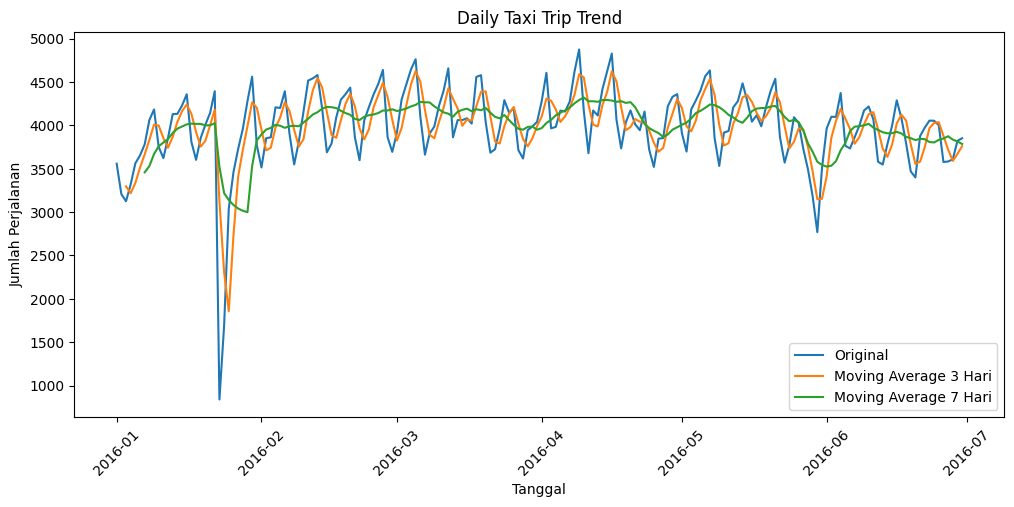

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(daily_summary["pickup_date"], daily_summary["trip_count"], label="Original")
plt.plot(daily_summary["pickup_date"], daily_summary["moving_avg_3"], label="Moving Average 3 Hari")
plt.plot(daily_summary["pickup_date"], daily_summary["moving_avg_7"], label="Moving Average 7 Hari")

plt.title("Daily Taxi Trip Trend")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Perjalanan")
plt.legend()
plt.xticks(rotation=45)
plt.show()

#**15. Weekday vs Weekend Pattern**

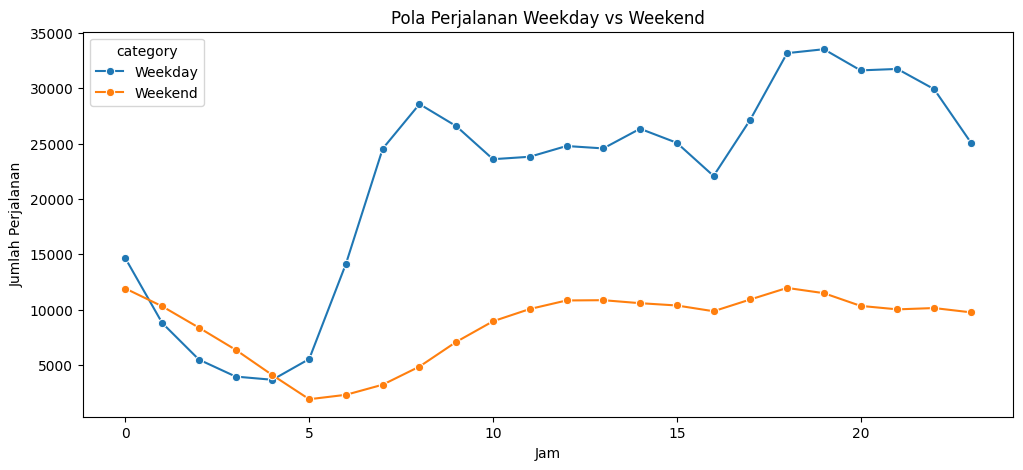

In [ ]:
weekday_weekend_hour = (
    df.groupby(["is_weekend", "pickup_hour"])
    .size()
    .reset_index(name="trip_count")
)

weekday_weekend_hour["category"] = weekday_weekend_hour["is_weekend"].map({
    0: "Weekday",
    1: "Weekend"
})

plt.figure(figsize=(12,5))
sns.lineplot(
    data=weekday_weekend_hour,
    x="pickup_hour",
    y="trip_count",
    hue="category",
    marker="o"
)

plt.title("Pola Perjalanan Weekday vs Weekend")
plt.xlabel("Jam")
plt.ylabel("Jumlah Perjalanan")
plt.show()

# Clustering Preparation

#**16. Sampling untuk Clustering**

In [ ]:
# Sampling agar clustering stabil dan tidak berat
df_cluster = df.copy()

print("Shape data clustering:", df_cluster.shape)

Shape data clustering: (724966, 22)


#**17. Pilih Fitur Clustering**

In [ ]:
cluster_features = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "pickup_hour",
    "is_weekend",
    "passenger_count",
    "distance_km",
    "trip_duration_min",
    "speed_kmph"
]

X = df_cluster[cluster_features].copy()
X = X.dropna()

print("Shape X:", X.shape)
display(X.head())

Shape X: (724966, 10)


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,pickup_hour,is_weekend,passenger_count,distance_km,trip_duration_min,speed_kmph
0,-73.953918,40.778873,-73.963875,40.771164,16,0,1,1.199073,6.666667,10.791654
1,-73.988312,40.731743,-73.994751,40.694931,23,0,2,4.129111,18.333333,13.513454
2,-73.997314,40.721458,-73.948029,40.774918,17,1,2,7.250753,27.250000,15.964960
3,-73.961670,40.759720,-73.956779,40.780628,9,0,6,2.361097,19.016667,7.449562
4,-74.017120,40.708469,-73.988182,40.740631,6,0,1,4.328534,14.133333,18.375851


#**18. Scaling**

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaling selesai.")
print("Shape X_scaled:", X_scaled.shape)

Scaling selesai.
Shape X_scaled: (724966, 10)


# K-Means Clustering

#**19. Elbow Method**

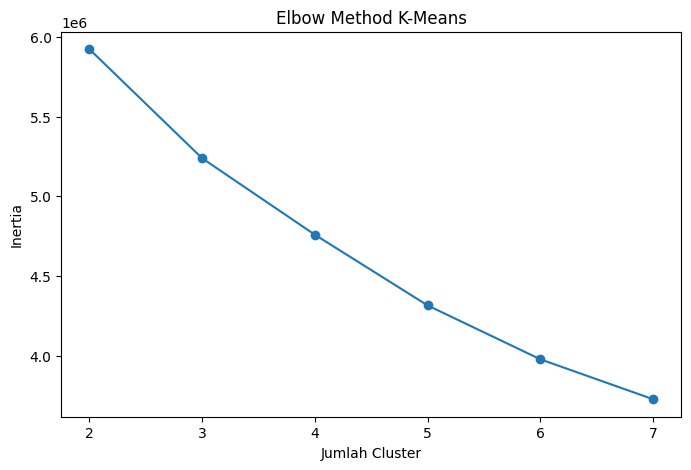

In [ ]:
K_range = range(2,8)
inertia = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K_range, inertia, marker="o")
plt.title("Elbow Method K-Means")
plt.xlabel("Jumlah Cluster")
plt.ylabel("Inertia")
plt.show()

#**20. Silhouette Score K-Means**

In [ ]:
# Silhouette pakai sample lebih kecil agar tidak berat

X_silhouette = X_scaled

kmeans_silhouette_scores = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_silhouette)

    score = silhouette_score(X_silhouette, labels)
    kmeans_silhouette_scores.append(score)

kmeans_eval = pd.DataFrame({
    "k": list(K_range),
    "inertia": inertia,
    "silhouette_score": kmeans_silhouette_scores
})

display(kmeans_eval)

#**21. Visualisasi Silhouette K-Means**

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(
    kmeans_eval["k"],
    kmeans_eval["silhouette_score"],
    marker="o"
)

plt.title("Silhouette Score K-Means")
plt.xlabel("Jumlah Cluster")
plt.ylabel("Silhouette Score")
plt.show()

#**22. Final K-Means**

In [ ]:
# Sesuaikan berdasarkan elbow dan silhouette.
# Jika ragu, gunakan k terbaik dari silhouette.

optimal_k = int(kmeans_eval.loc[kmeans_eval["silhouette_score"].idxmax(), "k"])

print("Optimal k berdasarkan silhouette:", optimal_k)

kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(X_scaled)

df_kmeans = X.copy()
df_kmeans["kmeans_cluster"] = kmeans_labels

print("Distribusi Cluster K-Means:")
display(df_kmeans["kmeans_cluster"].value_counts().sort_index())

#**23. Profil Cluster K-Means**

In [ ]:
kmeans_profile = (
    df_kmeans
    .groupby("kmeans_cluster")
    .agg(
        total_data=("distance_km", "count"),
        avg_distance_km=("distance_km", "mean"),
        avg_duration_min=("trip_duration_min", "mean"),
        avg_speed_kmph=("speed_kmph", "mean"),
        avg_pickup_hour=("pickup_hour", "mean"),
        avg_passenger=("passenger_count", "mean"),
        weekend_ratio=("is_weekend", "mean"),
        avg_pickup_lat=("pickup_latitude", "mean"),
        avg_pickup_lon=("pickup_longitude", "mean")
    )
    .reset_index()
)

display(kmeans_profile)

#**24. Visualisasi K-Means**

In [ ]:
plt.figure(figsize=(8,6))

scatter = plt.scatter(
    df_kmeans["distance_km"],
    df_kmeans["trip_duration_min"],
    c=df_kmeans["kmeans_cluster"],
    alpha=0.5,
    s=10
)

plt.title("K-Means Cluster: Distance vs Duration")
plt.xlabel("Distance KM")
plt.ylabel("Trip Duration Minute")
plt.colorbar(scatter, label="Cluster")
plt.show()

#**25. Visualisasi PCA K-Means**

In [ ]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df_kmeans["pca_1"] = X_pca[:, 0]
df_kmeans["pca_2"] = X_pca[:, 1]

plt.figure(figsize=(8,6))

scatter = plt.scatter(
    df_kmeans["pca_1"],
    df_kmeans["pca_2"],
    c=df_kmeans["kmeans_cluster"],
    alpha=0.5,
    s=10
)

plt.title("Visualisasi Cluster K-Means dengan PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(scatter, label="Cluster")
plt.show()

# DBSCAN sebagai Pembanding

#**26. DBSCAN**
Catatan: DBSCAN lebih berat daripada K-Means, jadi pakai sample lebih kecil.


In [ ]:
# DBSCAN menggunakan seluruh data

df_dbscan = X.copy()

scaler_dbscan = StandardScaler()
X_dbscan_scaled = scaler_dbscan.fit_transform(df_dbscan)

print("Shape data DBSCAN:", X_dbscan_scaled.shape)

#**27. DBSCAN Parameter Testing**

In [ ]:
eps_values = [0.3, 0.5, 0.7, 1.0, 1.2]
min_samples_values = [5, 10, 20]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan = DBSCAN(
            eps=0,7,
            min_samples=10,
            n_jobs=-1
        )

        labels = dbscan.fit_predict(X_dbscan_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_count = list(labels).count(-1)
        noise_ratio = noise_count / len(labels)

        if n_clusters > 1:
            try:
                score = silhouette_score(X_dbscan_scaled, labels)
            except:
                score = np.nan
        else:
            score = np.nan

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "noise_count": noise_count,
            "noise_ratio": noise_ratio,
            "silhouette_score": score
        })

dbscan_eval = pd.DataFrame(dbscan_results)

display(dbscan_eval.sort_values(
    by=["silhouette_score"],
    ascending=False
))

#**28. Final DBSCAN**

In [ ]:
# Ambil parameter terbaik dari hasil silhouette
best_dbscan = dbscan_eval.dropna().sort_values(
    by="silhouette_score",
    ascending=False
).iloc[0]

best_eps = best_dbscan["eps"]
best_min_samples = int(best_dbscan["min_samples"])

print("Best EPS:", best_eps)
print("Best Min Samples:", best_min_samples)

dbscan_final = DBSCAN(
    eps=best_eps,
    min_samples=best_min_samples
)

dbscan_labels = dbscan_final.fit_predict(X_dbscan_scaled)

df_dbscan = X.copy()
df_dbscan["dbscan_cluster"] = dbscan_labels

print("Distribusi Cluster DBSCAN:")
display(df_dbscan["dbscan_cluster"].value_counts().sort_index())

# **29. Profil Cluster DBSCAN**

In [ ]:
dbscan_profile = (
    df_dbscan
    .groupby("dbscan_cluster")
    .agg(
        total_data=("distance_km", "count"),
        avg_distance_km=("distance_km", "mean"),
        avg_duration_min=("trip_duration_min", "mean"),
        avg_speed_kmph=("speed_kmph", "mean"),
        avg_pickup_hour=("pickup_hour", "mean"),
        avg_passenger=("passenger_count", "mean"),
        weekend_ratio=("is_weekend", "mean")
    )
    .reset_index()
)

display(dbscan_profile)

# **30. Visualisasi DBSCAN**

In [ ]:
plt.figure(figsize=(8,6))

scatter = plt.scatter(
    df_dbscan["distance_km"],
    df_dbscan["trip_duration_min"],
    c=df_dbscan["dbscan_cluster"],
    alpha=0.5,
    s=10
)

plt.title("DBSCAN Cluster: Distance vs Duration")
plt.xlabel("Distance KM")
plt.ylabel("Trip Duration Minute")
plt.colorbar(scatter, label="Cluster")
plt.show()

# Perbandingan K-Means dan DBSCAN

# **31. Ringkasan Evaluasi**

In [ ]:
best_kmeans_score = kmeans_eval["silhouette_score"].max()

best_dbscan_score = dbscan_eval["silhouette_score"].max()

comparison = pd.DataFrame({
    "Metode": ["K-Means", "DBSCAN"],
    "Jumlah Cluster": [
        optimal_k,
        int(best_dbscan["n_clusters"])
    ],
    "Silhouette Score": [
        best_kmeans_score,
        best_dbscan_score
    ],
    "Catatan": [
        "Cocok untuk segmentasi umum dan dataset besar",
        "Cocok untuk pola berbasis kepadatan dan deteksi noise"
    ]
})

display(comparison)

# **32. Export Semua Output**

In [ ]:
HOURLY_PATH = OUTPUT_DIR / "hourly_summary.csv"
DAILY_PATH = OUTPUT_DIR / "daily_summary.csv"
KMEANS_PATH = OUTPUT_DIR / "kmeans_result.csv"
DBSCAN_PATH = OUTPUT_DIR / "dbscan_result.csv"
KMEANS_PROFILE_PATH = OUTPUT_DIR / "kmeans_profile.csv"
DBSCAN_PROFILE_PATH = OUTPUT_DIR / "dbscan_profile.csv"
COMPARISON_PATH = OUTPUT_DIR / "model_comparison.csv"

hourly_summary.to_csv(HOURLY_PATH, index=False)
daily_summary.to_csv(DAILY_PATH, index=False)
df_kmeans.to_csv(KMEANS_PATH, index=False)
df_dbscan.to_csv(DBSCAN_PATH, index=False)
kmeans_profile.to_csv(KMEANS_PROFILE_PATH, index=False)
dbscan_profile.to_csv(DBSCAN_PROFILE_PATH, index=False)
comparison.to_csv(COMPARISON_PATH, index=False)

print("Semua output berhasil disimpan di folder:")
print(OUTPUT_DIR)